In [1]:
!pip install scikit-learn pandas joblib matplotlib

# Library

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

# Data

In [3]:
df = pd.read_csv("student_lifestyle_dataset.csv")

print(df.shape)
print(df.head())
print(df.isna().sum())
print(df.columns.tolist())

print(df["Stress_Level"].value_counts())

(2000, 8)
   Student_ID  Study_Hours_Per_Day  Extracurricular_Hours_Per_Day  \
0           1                  6.9                            3.8   
1           2                  5.3                            3.5   
2           3                  5.1                            3.9   
3           4                  6.5                            2.1   
4           5                  8.1                            0.6   

   Sleep_Hours_Per_Day  Social_Hours_Per_Day  Physical_Activity_Hours_Per_Day  \
0                  8.7                   2.8                              1.8   
1                  8.0                   4.2                              3.0   
2                  9.2                   1.2                              4.6   
3                  7.2                   1.7                              6.5   
4                  6.5                   2.2                              6.6   

    GPA Stress_Level  
0  2.99     Moderate  
1  2.75          Low  
2  2.67          Lo

Pemeriksaan Dataset

In [4]:
print("UKURAN DATASET:")
print(df.shape)

print("\nNAMA KOLOM:")
print(df.columns.tolist())

print("\nTIPE DATA:")
print(df.dtypes)

print("\nMISSING VALUE:")
print(df.isna().sum())

print("\nJUMLAH DATA DUPLIKAT:")
print(df.duplicated().sum())

print("\nCONTOH DATA:")
display(df.head())

UKURAN DATASET:
(2000, 8)

NAMA KOLOM:
['Student_ID', 'Study_Hours_Per_Day', 'Extracurricular_Hours_Per_Day', 'Sleep_Hours_Per_Day', 'Social_Hours_Per_Day', 'Physical_Activity_Hours_Per_Day', 'GPA', 'Stress_Level']

TIPE DATA:
Student_ID                           int64
Study_Hours_Per_Day                float64
Extracurricular_Hours_Per_Day      float64
Sleep_Hours_Per_Day                float64
Social_Hours_Per_Day               float64
Physical_Activity_Hours_Per_Day    float64
GPA                                float64
Stress_Level                        object
dtype: object

MISSING VALUE:
Student_ID                         0
Study_Hours_Per_Day                0
Extracurricular_Hours_Per_Day      0
Sleep_Hours_Per_Day                0
Social_Hours_Per_Day               0
Physical_Activity_Hours_Per_Day    0
GPA                                0
Stress_Level                       0
dtype: int64

JUMLAH DATA DUPLIKAT:
0

CONTOH DATA:


,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High


Distribusi Kelas dan Visualisasi

JUMLAH MAHASISWA PER TINGKAT STRES:
Stress_Level
High        1029
Moderate     674
Low          297
Name: count, dtype: int64

PERSENTASE TINGKAT STRES:
Stress_Level
High        51.45
Moderate    33.70
Low         14.85
Name: proportion, dtype: float64


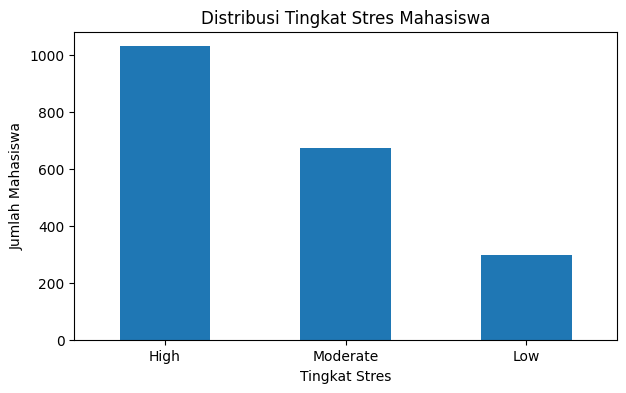

In [5]:
# Distribusi kategori tingkat stres

print("JUMLAH MAHASISWA PER TINGKAT STRES:")
print(df["Stress_Level"].value_counts())

print("\nPERSENTASE TINGKAT STRES:")
print(
    (df["Stress_Level"].value_counts(normalize=True) * 100)
    .round(2)
)

# Visualisasi distribusi kelas
import matplotlib.pyplot as plt

df["Stress_Level"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Distribusi Tingkat Stres Mahasiswa"
)

plt.xlabel("Tingkat Stres")
plt.ylabel("Jumlah Mahasiswa")
plt.xticks(rotation=0)
plt.show()

# Pemisahan Fitur

In [6]:
from sklearn.model_selection import train_test_split

TARGET = "Stress_Level"

FITUR = df.drop(
    columns=["Student_ID", TARGET],
    errors="ignore"
).columns.tolist()

X = df[FITUR]
y = df[TARGET]

# Membagi data training dan testing (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah Fitur:", len(FITUR))
print("Daftar Fitur:", FITUR)

print("Train:", X_train.shape, "| Test:", X_test.shape)

print("\nDistribusi Data Training:")
print(y_train.value_counts())

print("\nDistribusi Data Testing:")
print(y_test.value_counts())

Jumlah Fitur: 6
Daftar Fitur: ['Study_Hours_Per_Day', 'Extracurricular_Hours_Per_Day', 'Sleep_Hours_Per_Day', 'Social_Hours_Per_Day', 'Physical_Activity_Hours_Per_Day', 'GPA']
Train: (1600, 6) | Test: (400, 6)

Distribusi Data Training:
Stress_Level
High        823
Moderate    539
Low         238
Name: count, dtype: int64

Distribusi Data Testing:
Stress_Level
High        206
Moderate    135
Low          59
Name: count, dtype: int64


# Pipeline

In [7]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), FITUR)
])

# Model Deep Neural Network (DNN)
dnn = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    solver="adam",
    alpha=1e-3,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42
)

# Training

In [8]:
# ===== TRAINING MODEL DNN =====

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

# 1. Menentukan fitur dan target
TARGET = "Stress_Level"

FITUR = df.drop(
    columns=["Student_ID", TARGET],
    errors="ignore"
).columns.tolist()

X = df[FITUR]
y = df[TARGET]

# 2. Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Encode label target
le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

print("Mapping Label:")
print(dict(zip(le.classes_, le.transform(le.classes_))))

# 4. Preprocessing
preprocess = ColumnTransformer([
    ("num", StandardScaler(), FITUR)
])

# 5. Model DNN
dnn = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    solver="adam",
    alpha=1e-3,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42
)

# 6. Pipeline
model = Pipeline([
    ("preprocess", preprocess),
    ("dnn", dnn)
])

# 7. Training
model.fit(X_train, y_train_encoded)

# 8. Cek hasil training
mlp = model.named_steps["dnn"]

print("\nJumlah fitur:", len(FITUR))
print("Daftar fitur:", FITUR)
print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Epoch berjalan:", mlp.n_iter_)

if mlp.validation_scores_ is not None:
    print(
        "Akurasi validasi terbaik:",
        round(max(mlp.validation_scores_), 4)
    )

Mapping Label:
{'High': np.int64(0), 'Low': np.int64(1), 'Moderate': np.int64(2)}

Jumlah fitur: 6
Daftar fitur: ['Study_Hours_Per_Day', 'Extracurricular_Hours_Per_Day', 'Sleep_Hours_Per_Day', 'Social_Hours_Per_Day', 'Physical_Activity_Hours_Per_Day', 'GPA']
Train: (1600, 6)
Test: (400, 6)
Epoch berjalan: 54
Akurasi validasi terbaik: 0.9938


# Evaluasi data set

In [9]:
# ===== EVALUASI DATASET =====

import numpy as np

# 1. Prediksi data testing
y_pred = model.predict(X_test)

# 2. Accuracy dan F1 Macro
acc = accuracy_score(y_test_encoded, y_pred)

f1 = f1_score(
    y_test_encoded,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy : {acc:.4f}")
print(f"F1 Macro : {f1:.4f}")

# 3. Classification Report
target_names = le.classes_
labels = np.arange(len(target_names))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test_encoded,
    y_pred,
    labels=labels,
    target_names=target_names,
    zero_division=0
))

# 4. Confusion Matrix
cm = confusion_matrix(
    y_test_encoded,
    y_pred,
    labels=labels
)

print("\nCONFUSION MATRIX:")
print(pd.DataFrame(
    cm,
    index=[f"Asli_{l}" for l in target_names],
    columns=[f"Pred_{l}" for l in target_names]
))

# 5. Baseline Model
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train_encoded)

f1_base = f1_score(
    y_test_encoded,
    baseline.predict(X_test),
    average="macro",
    zero_division=0
)

print(f"\nF1 Baseline: {f1_base:.4f}")

Accuracy : 0.9600
F1 Macro : 0.9521

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        High       0.97      0.98      0.97       206
         Low       0.95      0.92      0.93        59
    Moderate       0.96      0.95      0.95       135

    accuracy                           0.96       400
   macro avg       0.96      0.95      0.95       400
weighted avg       0.96      0.96      0.96       400


CONFUSION MATRIX:
               Pred_High  Pred_Low  Pred_Moderate
Asli_High            202         2              2
Asli_Low               1        54              4
Asli_Moderate          6         1            128

F1 Baseline: 0.2266


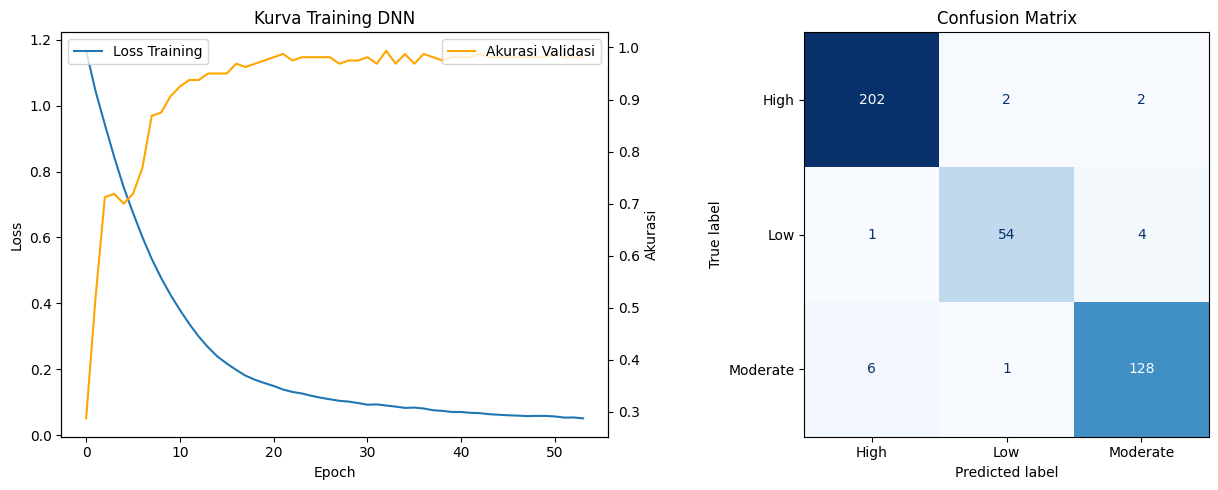

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

# Prediksi data test
y_pred = model.predict(X_test)

# Nama kelas
target_names = le.classes_

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# 1. Kurva Training DNN
ax1 = ax[0]
ax2 = ax1.twinx()

ax1.plot(mlp.loss_curve_, label="Loss Training")
ax2.plot(mlp.validation_scores_, color="orange",
         label="Akurasi Validasi")

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax2.set_ylabel("Akurasi")

ax1.set_title("Kurva Training DNN")

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

# 2. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_encoded,
    y_pred,
    labels=np.arange(len(target_names)),
    display_labels=target_names,
    cmap="Blues",
    ax=ax[1],
    colorbar=False
)

ax[1].set_title("Confusion Matrix")

plt.tight_layout()
plt.show()

# Gerbang Evaluasi & Simpan Model

In [11]:
# ===== GERBANG EVALUASI & SIMPAN MODEL =====

from sklearn.metrics import accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
import joblib
import json

# 1. Prediksi model DNN
y_pred = model.predict(X_test)

# 2. Accuracy dan F1 DNN
acc = accuracy_score(y_test_encoded, y_pred)

f1 = f1_score(
    y_test_encoded,
    y_pred,
    average="macro",
    zero_division=0
)

# 3. Baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train_encoded)

y_pred_base = baseline.predict(X_test)

f1_base = f1_score(
    y_test_encoded,
    y_pred_base,
    average="macro",
    zero_division=0
)

# 4. Menampilkan hasil
print("=== HASIL EVALUASI DNN ===")
print("Accuracy DNN :", round(acc, 4))
print("F1 Macro DNN :", round(f1, 4))
print("F1 Baseline  :", round(f1_base, 4))

=== HASIL EVALUASI DNN ===
Accuracy DNN : 0.96
F1 Macro DNN : 0.9521
F1 Baseline  : 0.2266


In [12]:
# ===== GERBANG EVALUASI & SIMPAN MODEL =====

import joblib
import json
import sklearn
import pandas as pd
import numpy as np

# Target evaluasi
TARGET_F1 = 0.80

# Pemeriksaan kelulusan model
if f1 >= TARGET_F1 and f1 > f1_base:

    # 1. Simpan model DNN
    joblib.dump(model, "model_student_stress.pkl")

    # 2. Simpan Label Encoder
    joblib.dump(le, "label_encoder.pkl")

    # 3. Informasi model
    info = {
        "nama_model": "DNN (MLPClassifier 64-32-16)",
        "dataset": "Student Stress Prediction",
        "fitur": FITUR,
        "target": TARGET,
        "kelas": [str(x) for x in le.classes_],

        "rentang_fitur": {
            c: [float(df[c].min()), float(df[c].max())]
            for c in FITUR
        },

        "metrik": {
            "accuracy": round(acc, 4),
            "f1_macro": round(f1, 4),
            "f1_baseline": round(f1_base, 4),
            "n_test": int(len(y_test))
        },

        "versi": {
            "scikit-learn": sklearn.__version__,
            "pandas": pd.__version__,
            "numpy": np.__version__,
            "joblib": joblib.__version__
        }
    }

    # 4. Simpan informasi model
    with open("model_info.json", "w", encoding="utf-8") as f:
        json.dump(info, f, indent=2, ensure_ascii=False)

    print("LOLOS EVALUASI!")
    print("Model DNN berhasil disimpan.")
    print("File: model_student_stress.pkl")
    print("File: label_encoder.pkl")
    print("File: model_info.json")

else:
    print(
        f"BELUM LOLOS "
        f"(F1 = {f1:.4f}, target = {TARGET_F1}) "
        "-> perbaiki model, jangan deploy"
    )

LOLOS EVALUASI!
Model DNN berhasil disimpan.
File: model_student_stress.pkl
File: label_encoder.pkl
File: model_info.json


# Uji Muat Ulang Model

In [13]:
# ===== UJI COBA MODEL STUDENT STRESS =====

import joblib
import pandas as pd
import json

# 1. Load model DNN
model = joblib.load("model_student_stress.pkl")

# 2. Load Label Encoder
le = joblib.load("label_encoder.pkl")

# 3. Load informasi model
with open("model_info.json", "r", encoding="utf-8") as f:
    info = json.load(f)

# 4. Mengambil satu contoh data mahasiswa dari data testing
contoh = X_test.iloc[[0]].copy()

print("=== DATA MAHASISWA ===")
print(contoh)

# 5. Prediksi
prediksi_encoded = model.predict(contoh)

prediksi = le.inverse_transform(
    prediksi_encoded.astype(int)
)

print("\n=== HASIL PREDIKSI ===")
print("Prediksi Tingkat Stres:", prediksi[0])

# 6. Probabilitas prediksi
proba = model.predict_proba(contoh)[0]

print("\n=== PROBABILITAS PREDIKSI ===")

for kelas, p in zip(le.classes_, proba):
    print(f"{kelas}: {p * 100:.2f}%")

=== DATA MAHASISWA ===
      Study_Hours_Per_Day  Extracurricular_Hours_Per_Day  Sleep_Hours_Per_Day  \
1684                  5.1                            2.8                  7.4   

      Social_Hours_Per_Day  Physical_Activity_Hours_Per_Day   GPA  
1684                   0.7                              8.0  3.15  

=== HASIL PREDIKSI ===
Prediksi Tingkat Stres: Low

=== PROBABILITAS PREDIKSI ===
High: 0.03%
Low: 99.70%
Moderate: 0.27%


In [14]:
from google.colab import files

files.download("model_student_stress.pkl")
files.download("label_encoder.pkl")
files.download("model_info.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>